# Speech Emotion Recognition — CREMA-D

Classify the emotion expressed in a short spoken sentence into one of six classes:
**angry, disgust, fear, happy, neutral, sad**.

**Dataset:** [CREMA-D](https://github.com/CheyneyComputerScience/CREMA-D): 7,442 clips from 91 actors reading 12 sentences.
File names encode `actor_sentence_emotion_intensity`, e.g. `1001_DFA_ANG_XX.wav`.

**Approach**
1. Explore the data.
2. Extract a fixed-length vector of hand-crafted acoustic features per clip (MFCCs and deltas, log-mel, chroma, spectral shape, energy, pitch).
3. Evaluate **speaker-independently**: test actors never appear in training. A random split lets models memorise voices and inflates accuracy.
4. Compare classifiers, tune hyperparameters with actor-grouped cross-validation, and build the final ensemble.
5. Analyse errors and demo inference on single files.

The reusable code lives in the `ser/` package; `train.py` and `predict.py` are the command-line entry points.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio, display

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from xgboost import XGBClassifier

import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # notebooks/ -> repo root, so `ser` is importable

from ser.features import build_metadata, load_audio, SAMPLE_RATE
from ser.data import DATA_DIR, load_features, speaker_split, xy
from ser.model import build_model, save_model, predict_file

plt.rcParams["figure.dpi"] = 100
EMOTION_ORDER = ["angry", "disgust", "fear", "happy", "neutral", "sad"]

## 1. Data exploration

In [2]:
meta = build_metadata(DATA_DIR)
print(f"{len(meta)} clips, {meta.actor.nunique()} actors, {meta.sentence.nunique()} sentences")
meta.head()

7442 clips, 91 actors, 12 sentences


,path,actor,sentence,emotion,intensity
0,C:\Users\pc\Desktop\Projects\Speech-Emotion-Re...,1001,DFA,angry,XX
1,C:\Users\pc\Desktop\Projects\Speech-Emotion-Re...,1001,DFA,disgust,XX
2,C:\Users\pc\Desktop\Projects\Speech-Emotion-Re...,1001,DFA,fear,XX
3,C:\Users\pc\Desktop\Projects\Speech-Emotion-Re...,1001,DFA,happy,XX
4,C:\Users\pc\Desktop\Projects\Speech-Emotion-Re...,1001,DFA,neutral,XX


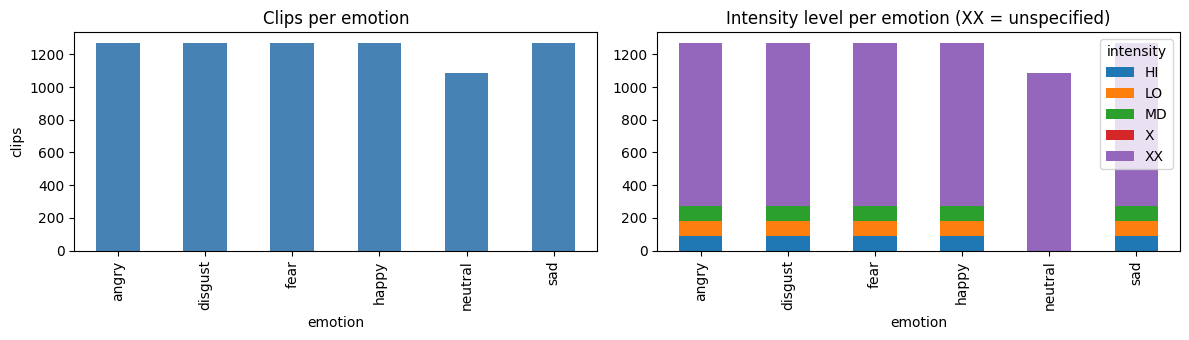

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
meta.emotion.value_counts().reindex(EMOTION_ORDER).plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Clips per emotion"); axes[0].set_ylabel("clips")
pd.crosstab(meta.emotion, meta.intensity).reindex(EMOTION_ORDER).plot.bar(stacked=True, ax=axes[1])
axes[1].set_title("Intensity level per emotion (XX = unspecified)")
plt.tight_layout()

The classes are balanced, except *neutral*, which has no intensity variants. Only one sentence (`IEO`) was recorded at LO/MD/HI intensity.

count    7442.000000
mean        2.542884
std         0.505979
min         1.267937
25%         2.202187
50%         2.502500
75%         2.836187
max         5.005000
Name: duration, dtype: float64

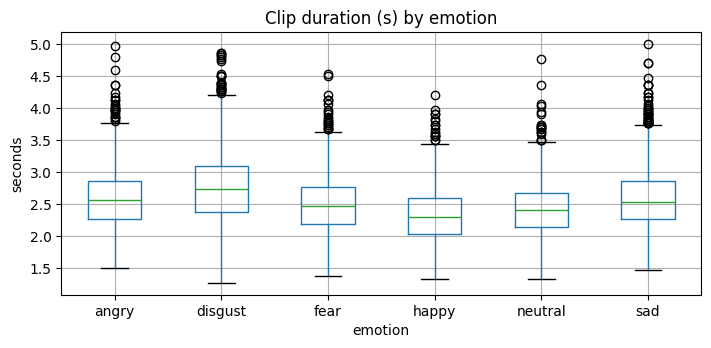

In [4]:
durations = meta.path.map(lambda p: librosa.get_duration(path=p))
meta["duration"] = durations
ax = meta.boxplot(column="duration", by="emotion", figsize=(8, 3.5))
plt.suptitle(""); ax.set_title("Clip duration (s) by emotion"); ax.set_ylabel("seconds")
meta.duration.describe()

### Listening to and looking at one sentence in each emotion

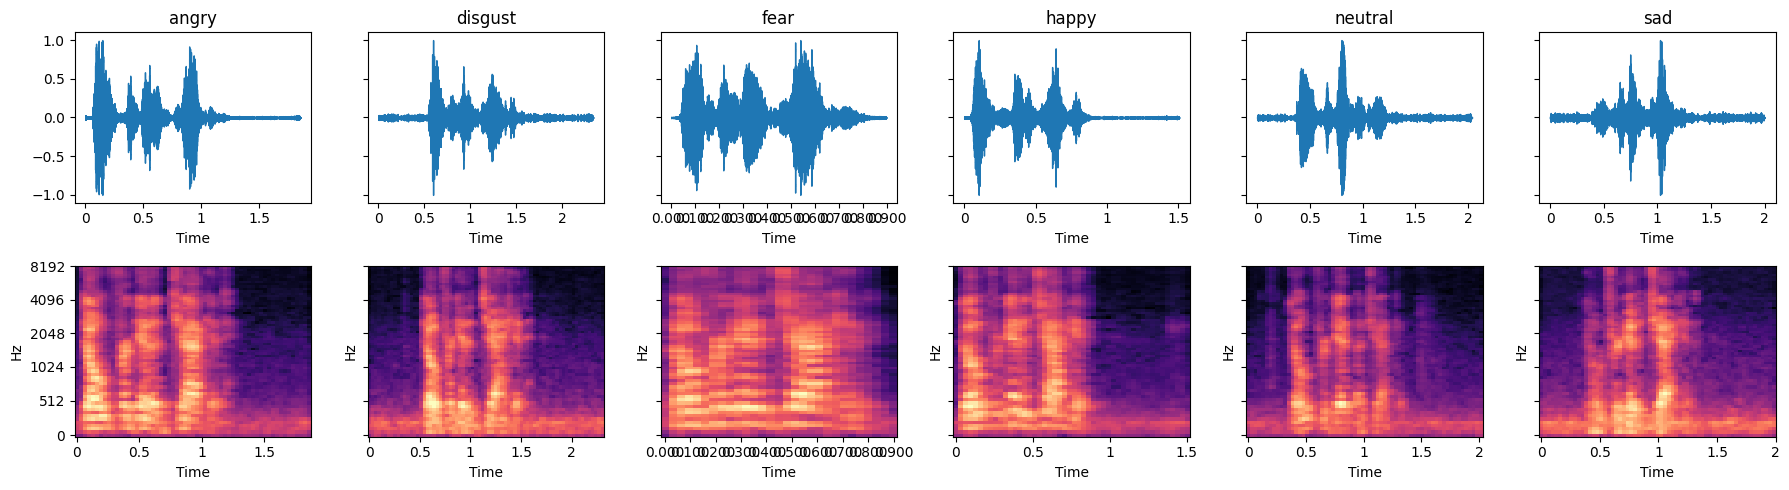

In [5]:
examples = meta[(meta.actor == 1001) & (meta.sentence == "DFA")].set_index("emotion").loc[EMOTION_ORDER]
fig, axes = plt.subplots(2, 6, figsize=(18, 5), sharey="row")
for i, (emotion, row) in enumerate(examples.iterrows()):
    y = load_audio(row.path)
    librosa.display.waveshow(y, sr=SAMPLE_RATE, ax=axes[0, i])
    axes[0, i].set_title(emotion)
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SAMPLE_RATE, n_mels=64), ref=np.max)
    librosa.display.specshow(S, sr=SAMPLE_RATE, x_axis="time", y_axis="mel", ax=axes[1, i])
plt.tight_layout()
display(Audio(examples.loc["angry"].path), Audio(examples.loc["sad"].path))

Anger shows up as louder, denser high-frequency energy. Sadness is quieter and slower, with less energy in the upper mel bands.
The features below are designed to summarise these differences.

## 2. Feature extraction

Each clip is resampled to 16 kHz, silence is trimmed, and the signal is peak-normalised. Then `ser.features.extract_features` computes frame-level descriptors and summarises each by its **mean and standard deviation over time**:

| block | dims | what it captures |
|---|---|---|
| MFCC (40) + Δ + ΔΔ | 240 | vocal-tract timbre and its dynamics |
| log-mel (64 bands) | 128 | energy distribution across frequency |
| chroma (12) | 24 | pitch-class content |
| spectral contrast (6) | 12 | peak/valley structure (harmonicity) |
| centroid, bandwidth, roll-off, flatness, RMS, ZCR | 12 | brightness, loudness, noisiness |
| f0 via YIN (mean/std/min/max/median) | 5 | prosody / intonation |
| duration | 1 | speaking rate proxy |

Total: **422 features**. Extraction runs in parallel with joblib and is cached to `artifacts/features.pkl`; the first run takes about 2 minutes.

In [6]:
t = time.time()
df = load_features(verbose=0)
print(f"features: {df.shape}  ({time.time() - t:.1f}s)")
df.iloc[:5, :10]

features: (7442, 427)  (0.0s)


,path,actor,sentence,emotion,intensity,mfcc_0_mean,mfcc_1_mean,mfcc_2_mean,mfcc_3_mean,mfcc_4_mean
0,C:\Users\pc\Desktop\Projects\Speech-Emotion-Re...,1001,DFA,angry,XX,-261.611847,68.686043,6.554764,19.597914,6.084146
1,C:\Users\pc\Desktop\Projects\Speech-Emotion-Re...,1001,DFA,disgust,XX,-260.040680,70.531494,10.483494,24.180197,13.704653
2,C:\Users\pc\Desktop\Projects\Speech-Emotion-Re...,1001,DFA,fear,XX,-181.857590,61.812344,-8.482599,13.210012,1.572030
3,C:\Users\pc\Desktop\Projects\Speech-Emotion-Re...,1001,DFA,happy,XX,-277.208405,69.026993,4.099956,21.615667,7.318747
4,C:\Users\pc\Desktop\Projects\Speech-Emotion-Re...,1001,DFA,neutral,XX,-260.341888,74.073364,9.583662,22.645660,10.133086


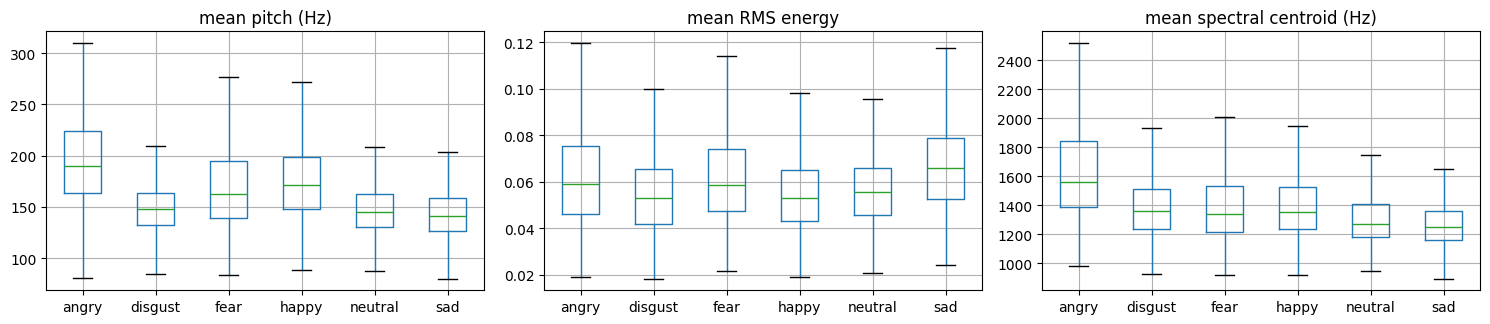

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col, title in zip(axes, ["f0_mean", "rms_mean", "centroid_mean"],
                          ["mean pitch (Hz)", "mean RMS energy", "mean spectral centroid (Hz)"]):
    df.boxplot(column=col, by="emotion", ax=ax, showfliers=False)
    ax.set_title(title); ax.set_xlabel("")
plt.suptitle(""); plt.tight_layout()

Single features already separate the classes partly. Anger, fear and happiness are high-arousal (higher energy and brighter spectrum), while sadness is low-arousal.
Separating emotions with similar arousal, such as happy vs. angry or neutral vs. sad, is the hard part.

## 3. Speaker-independent split

`GroupShuffleSplit` on `actor` holds out 20% of the actors. All model selection below uses `GroupKFold` on the training actors only, so the test set is touched just once per model.

In [8]:
train, test = speaker_split(df)
X_train, y_train = xy(train)
X_test, y_test = xy(test)
assert not set(train.actor) & set(test.actor)
print(f"train: {len(train)} clips / {train.actor.nunique()} actors")
print(f"test:  {len(test)} clips / {test.actor.nunique()} actors")

train: 5890 clips / 72 actors
test:  1552 clips / 19 actors


## 4. Baseline model comparison

In [9]:
le = LabelEncoder().fit(y_train)
candidates = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(C=10)),
    "MLP": make_pipeline(StandardScaler(), MLPClassifier((512, 256), alpha=1e-2, early_stopping=True, max_iter=300, random_state=0)),
    "Random forest": RandomForestClassifier(500, n_jobs=-1, random_state=0),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, subsample=0.8,
                             colsample_bytree=0.5, tree_method="hist", n_jobs=-1),
}
rows = []
for name, clf in candidates.items():
    t = time.time()
    clf.fit(X_train, le.transform(y_train))
    pred = le.inverse_transform(clf.predict(X_test))
    rows.append({"model": name, "accuracy": accuracy_score(y_test, pred),
                 "macro F1": f1_score(y_test, pred, average="macro"), "fit time (s)": time.time() - t})
results = pd.DataFrame(rows).set_index("model").round(3)
results

,accuracy,macro F1,fit time (s)
model,,,
Logistic regression,0.522,0.519,2.672
SVM (RBF),0.516,0.511,19.580
MLP,0.515,0.516,8.477
Random forest,0.469,0.449,16.339
XGBoost,0.523,0.517,128.059


## 5. Hyperparameter tuning (actor-grouped CV)

The two strongest fast models are tuned with 5-fold `GroupKFold` on the training actors.

In [10]:
cv = GroupKFold(n_splits=5)
searches = {
    "logreg": GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
                           {"logisticregression__C": [0.01, 0.03, 0.1, 0.3]}, cv=cv, n_jobs=-1),
    "svm": GridSearchCV(make_pipeline(StandardScaler(), SVC()),
                        {"svc__C": [3, 10], "svc__gamma": ["scale", 0.0005]}, cv=cv, n_jobs=-1),
}
for name, gs in searches.items():
    gs.fit(X_train, y_train, groups=train.actor)
    print(f"{name:7s} best={gs.best_params_}  cv acc={gs.best_score_:.3f}")

logreg  best={'logisticregression__C': 0.03}  cv acc=0.532


svm     best={'svc__C': 10, 'svc__gamma': 0.0005}  cv acc=0.556


## 6. Final model: soft-voting ensemble

`ser.model.build_model` averages the class probabilities of the tuned logistic regression, the tuned SVM and the MLP. The three models make somewhat different errors, so averaging gives a small but consistent gain. It matches XGBoost's accuracy while training several times faster.

In [11]:
t = time.time()
model = build_model().fit(X_train, y_train)
pred = model.predict(X_test)
print(f"fit time {time.time() - t:.0f}s")
print(f"accuracy {accuracy_score(y_test, pred):.3f}   macro F1 {f1_score(y_test, pred, average='macro'):.3f}")
print(classification_report(y_test, pred, digits=3))

fit time 75s
accuracy 0.532   macro F1 0.531
              precision    recall  f1-score   support

       angry      0.645     0.679     0.662       265
     disgust      0.460     0.517     0.487       265
        fear      0.525     0.506     0.515       265
       happy      0.474     0.483     0.479       265
     neutral      0.552     0.489     0.519       227
         sad      0.542     0.509     0.525       265

    accuracy                          0.532      1552
   macro avg      0.533     0.531     0.531      1552
weighted avg      0.533     0.532     0.531      1552



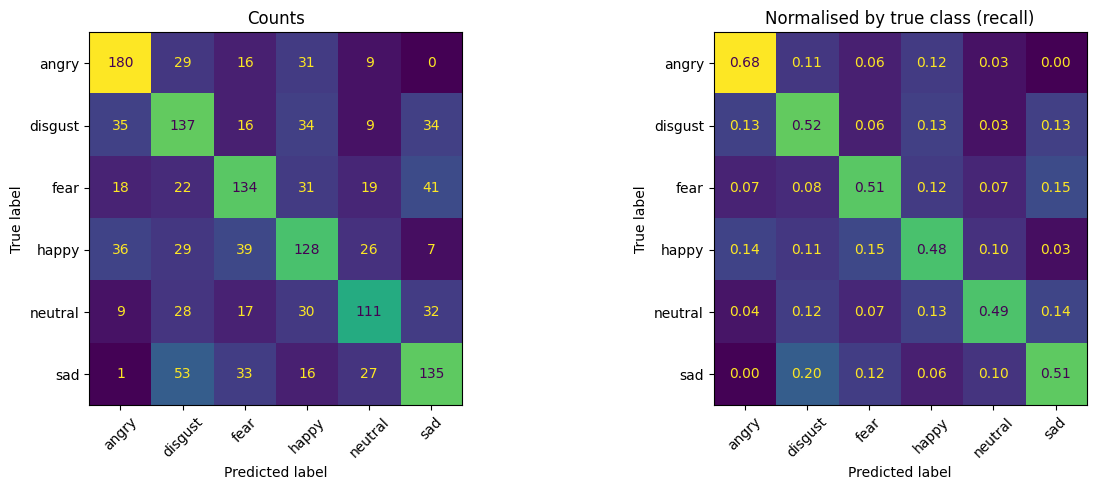

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=EMOTION_ORDER, ax=axes[0], colorbar=False)
axes[0].set_title("Counts")
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=EMOTION_ORDER, normalize="true",
                                        values_format=".2f", ax=axes[1], colorbar=False)
axes[1].set_title("Normalised by true class (recall)")
for ax in axes: ax.tick_params(axis="x", rotation=45)
plt.tight_layout()

## 7. Error analysis

per-actor accuracy ranges from 0.28 to 0.74


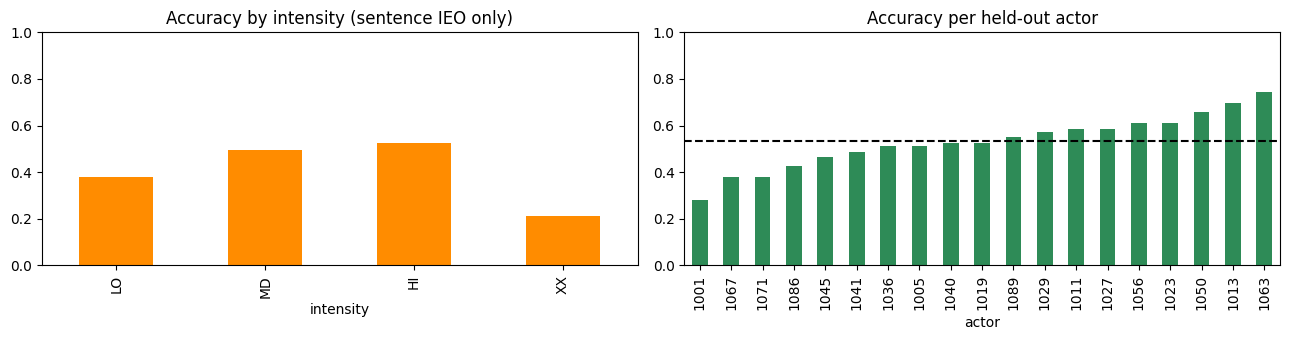

In [13]:
test_eval = test[["actor", "sentence", "emotion", "intensity"]].assign(correct=(pred == y_test))
by_intensity = test_eval[test_eval.sentence == "IEO"].groupby("intensity").correct.mean()
by_actor = test_eval.groupby("actor").correct.mean().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
by_intensity.reindex(["LO", "MD", "HI", "XX"]).plot.bar(ax=axes[0], color="darkorange")
axes[0].set_title("Accuracy by intensity (sentence IEO only)"); axes[0].set_ylim(0, 1)
by_actor.plot.bar(ax=axes[1], color="seagreen")
axes[1].axhline(by_actor.mean(), ls="--", c="k"); axes[1].set_title("Accuracy per held-out actor")
axes[1].set_ylim(0, 1)
plt.tight_layout()
print(f"per-actor accuracy ranges from {by_actor.min():.2f} to {by_actor.max():.2f}")

**Observations**
- **Anger** is by far the easiest class (~68% recall). **Happy** is the hardest (~48%) and leaks mostly into the other high-arousal classes, fear and angry.
- Most errors stay on the same arousal level. Angry and sad are almost never confused with each other, while **sad ↔ disgust** is the most common low-arousal mix-up.
- Intensity matters: on sentence `IEO`, **HI** clips are recognised ~53% of the time vs ~38% for **LO**. The `XX` bar here is only the 19 neutral IEO clips.
- Accuracy varies a lot between speakers. Some actors are much more expressive than others, which is the main limit of a speaker-independent system.

For context: 16.7% is chance, and the CREMA-D authors report that human raters identified the intended emotion from **audio alone only ~41%** of the time.
Deep models using self-supervised speech representations (e.g. wav2vec 2.0 / HuBERT) are the natural next step, at the cost of a GPU and much heavier dependencies.

## 8. Save the model and run inference

The notebook saves the model trained on the training actors. Run `python train.py --full` to refit on all 91 actors for deployment.

In [14]:
save_model(model)
# a few random clips from held-out actors
for _, row in test.sample(6, random_state=1).iterrows():
    label, scores = predict_file(model, row.path)
    top = ", ".join(f"{k} {v:.2f}" for k, v in sorted(scores.items(), key=lambda kv: -kv[1])[:3])
    mark = "OK " if label == row.emotion else "   "
    print(f"{mark} true={row.emotion:8s} pred={label:8s} ({top})")

OK  true=sad      pred=sad      (sad 0.88, disgust 0.06, fear 0.03)
OK  true=neutral  pred=neutral  (neutral 0.46, fear 0.32, happy 0.11)
    true=disgust  pred=angry    (angry 0.60, disgust 0.32, happy 0.06)
    true=angry    pred=disgust  (disgust 0.59, happy 0.19, fear 0.10)
OK  true=sad      pred=sad      (sad 0.46, disgust 0.28, fear 0.21)


OK  true=disgust  pred=disgust  (disgust 0.73, fear 0.16, sad 0.08)
